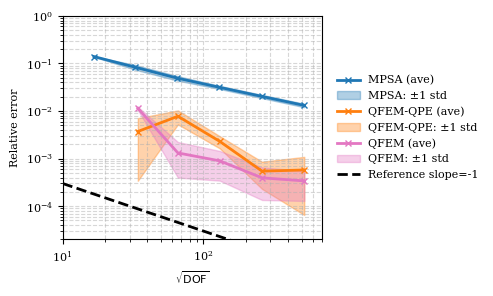

In [3]:
# Only for plot SIF results for all grid sizes
from __future__ import annotations
from dataclasses import dataclass

import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import LogLocator, LogFormatterMathtext

# MPSA
mpsa_dofs = np.array([
    16.71147518, 32.58541516, 65.12815506, 130.30222739, 260.65320118, 520.42549162
])

err_ave_mpsa = np.array([
    0.13963804, 0.08381346, 0.04920389, 0.03152079, 0.02030223, 0.01313669
]) 

err_std_mpsa = np.array([
    0.00170536, 0.00939047, 0.00535213, 0.00237731, 0.00159368, 0.00109355
]) 

# TPSA
# tpsa_dofs = np.array([
#     16.00, 31.43246729, 61.28621378, 122.01639234, 244.03688246, 487.59614437
# ])

# err_ave_tpsa = np.array([
#     0.20176096, 0.08363013, 0.03283475, 0.02955756, 0.01646297, 0.01414549
# ]) 

# err_std_tpsa = np.array([
#     0.0041435, 0.00630649, 0.0028787,  0.00337735, 0.00216976, 0.0014092
# ]) 

# QFEM-QPE
femqpe_dofs = np.array([
    34.25062305, 66.02453782, 131.1133649, 261.46259029, 522.16507555
])

err_ave_femqpe = np.array([
    0.00370928, 0.00776501, 0.00229425, 0.00054491, 0.00057612
]) 

err_std_femqpe = np.array([
    0.00336796, 0.00253469, 0.00065855, 0.0003145, 0.00051088
]) 

# QFEM
fem_dofs = np.array([
    34.25062305, 66.02453782, 131.1133649, 261.46259029, 522.16507555
])

err_ave_fem = np.array([
    0.01143342, 0.00131504, 0.00089459, 0.00039374, 0.00033936
]) 

err_std_fem = np.array([
    0.00091669, 0.00091639, 0.00055085, 0.00025887, 0.0002106
]) 

# Reference line
num_dofs_line = np.array([10, 30, 50, 70, 90, 100, 300, 500, 1000])
initial_value_line = 3e-4
first_order_line = initial_value_line * (num_dofs_line[0] / num_dofs_line)
half_order_line = initial_value_line  * (num_dofs_line[0] / num_dofs_line) ** 0.5

# Plot SIF KI
mpl.rcParams.update({
    "font.family": "serif",     
    "font.size": 8,             
    "axes.labelsize": 8,       
    "axes.titlesize": 8,        
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "lines.linewidth": 1.0,      
    "lines.markersize": 3.0,       
    "mathtext.fontset": "dejavusans",  
})
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))   # Scientific form

fig, ax = plt.subplots(figsize=(5.0, 3.0))   # inches
# MPSA
ax.loglog(
    mpsa_dofs,
    err_ave_mpsa,
    'x-',
    color='tab:blue',
    linewidth=2.0, 
    markersize=4.0,
    label="MPSA (ave)"
)
ax.fill_between(
    mpsa_dofs,
    err_ave_mpsa - err_std_mpsa,
    err_ave_mpsa + err_std_mpsa,
    color='tab:blue',
    alpha=0.35,
    label="MPSA: ±1 std"
)

# TPSA
# ax.loglog(
#     tpsa_dofs,
#     err_ave_tpsa,
#     'x-',
#     color='tab:green',
#     linewidth=2.0, 
#     markersize=4.0,
#     label="TPSA (ave)"
# )
# ax.fill_between(
#     tpsa_dofs,
#     err_ave_tpsa - err_std_tpsa,
#     err_ave_tpsa + err_std_tpsa,
#     color='tab:green',
#     alpha=0.35,
#     label="TPSA: ±1 std"
# )

# QFEM-QPE
ax.loglog(
    femqpe_dofs,
    err_ave_femqpe,
    'x-',
    color='tab:orange',
    linewidth=2.0, 
    markersize=4.0,
    label="QFEM-QPE (ave)"
)
ax.fill_between(
    femqpe_dofs,
    err_ave_femqpe - err_std_femqpe,
    err_ave_femqpe + err_std_femqpe,
    color='tab:orange',
    alpha=0.35,
    label="QFEM-QPE: ±1 std"
)

# QFEM
ax.loglog(
    fem_dofs,
    err_ave_fem,
    'x-',
    color='tab:pink',
    linewidth=2.0, 
    markersize=4.0,
    label="QFEM (ave)"
)
ax.fill_between(
    fem_dofs,
    err_ave_fem - err_std_fem,
    err_ave_fem + err_std_fem,
    color='tab:pink',
    alpha=0.35,
    label="QFEM: ±1 std"
)

ax.loglog(
    num_dofs_line, first_order_line,
    '--', color='k',
    linewidth=2.0,
    label="Reference slope=-1"
)

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.set_xlim(10, 700)
ax.set_ylim(0.00002, 1.0)
ax.xaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_major_formatter(LogFormatterMathtext())
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))

ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_formatter(LogFormatterMathtext())
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))

ax.set_xlabel(r"$\sqrt{\mathrm{DOF}}$")
ax.set_ylabel("Relative error")

# ax.legend(loc="lower left")
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),  
    frameon=False
)
ax.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
# plt.savefig("KII_convergence_ws.tiff", format="tiff", dpi=300, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})
# plt.savefig("sneddon_singularity.eps", format="eps", dpi=300, bbox_inches="tight")
plt.show()